# Analisis Historis IHSG (1995–2025)
## 30 Tahun Pergerakan Pasar Modal Indonesia

**Dataset:** IHSG Daily Historical Price (Jakarta Composite Index)

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

In [2]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

df = pd.read_csv('../data/ihsg_daily.csv')
df.head()

,Date,Open,High,Low,Close,Volume
0,1995-01-02,470.121735,470.121735,470.121735,470.121735,0
1,1995-01-03,472.361633,472.361633,472.361633,472.361633,0
2,1995-01-04,474.471527,474.471527,474.471527,474.471527,0
3,1995-01-05,477.801422,477.801422,477.801422,477.801422,0
4,1995-01-06,481.201263,481.201263,481.201263,481.201263,0


## 1. Struktur Dataset

In [3]:
print('Shape:', df.shape)
df.info()

Shape: (7681, 6)
<class 'pandas.DataFrame'>
RangeIndex: 7681 entries, 0 to 7680
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    7681 non-null   str    
 1   Open    7681 non-null   float64
 2   High    7681 non-null   float64
 3   Low     7681 non-null   float64
 4   Close   7681 non-null   float64
 5   Volume  7681 non-null   int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 360.2 KB


| No | Variabel | Tipe Data | Deskripsi |
| -: | -------- | --------- | --------- |
| 1 | Date | Object | Tanggal spesifik saat bursa saham beroperasi melakukan transaksi perdagangan. |
| 2 | Open | Float | Nilai atau posisi IHSG saat pasar resmi dibuka di sesi pagi hari. |
| 3 | High | Float | Angka puncak (tertinggi) yang berhasil dicapai IHSG dalam satu hari perdagangan. |
| 4 | Low | Float | Angka paling bawah (terendah) yang disentuh IHSG pada hari perdagangan tersebut. |
| 5 | Close | Float | Nilai akhir IHSG saat pasar ditutup. Kolom yang paling sering digunakan untuk melihat tren jangka panjang. |
| 6 | Volume | Integer | Total aktivitas atau jumlah unit transaksi yang terjadi di pasar pada tanggal tersebut. |


## 2. Cek Missing Values & Duplikat

In [4]:
df['Date'] = pd.to_datetime(df['Date'])

print('Missing values per kolom:')
print(df.isnull().sum())
print()
print('Tanggal duplikat:', df['Date'].duplicated().sum())
print('Baris duplikat penuh:', df.duplicated().sum())
print()
print('Rentang tanggal:', df['Date'].min().date(), 'hingga', df['Date'].max().date())

Missing values per kolom:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Tanggal duplikat: 0
Baris duplikat penuh: 0

Rentang tanggal: 1995-01-02 hingga 2026-08-03


## 3. Cek Anomali — Volume 0

Volume bernilai 0 mengindikasikan tidak ada aktivitas transaksi tercatat pada hari tersebut. Ini perlu dicek apakah tersebar merata atau terkonsentrasi pada periode tertentu (misalnya awal data ketika sistem pencatatan volume belum konsisten).

In [5]:
vol_zero = df[df['Volume'] == 0]
print('Jumlah baris dengan Volume = 0:', len(vol_zero), 'dari', len(df))
print()
print('Distribusi per tahun:')
print(vol_zero['Date'].dt.year.value_counts().sort_index())

Jumlah baris dengan Volume = 0: 109 dari 7681

Distribusi per tahun:
Date
1995    100
2017      1
2019      1
2020      4
2021      1
2022      1
2026      1
Name: count, dtype: int64


**Catatan:** Volume = 0 hampir seluruhnya terkonsentrasi di tahun 1995 (awal periode data), kemungkinan besar karena pencatatan volume transaksi belum konsisten pada masa awal bursa saham Indonesia beroperasi. Baris-baris ini **tidak dihapus** karena `Close` tetap valid dan digunakan sebagai basis analisis harga, namun perlu menjadi catatan keterbatasan data (data limitation) terutama jika ada analisis yang melibatkan Volume di awal periode.

## 4. Statistik Deskriptif

In [6]:
numeric_cols = ['Open', 'High', 'Low', 'Close', 'Volume']
df[numeric_cols].describe()

,Open,High,Low,Close,Volume
count,7681.000000,7681.000000,7681.000000,7681.000000,7.681000e+03
mean,3364.405692,3383.506375,3341.739543,3363.547367,7.006410e+07
std,2554.579779,2566.533734,2539.190130,2552.445623,2.227871e+08
min,257.513955,261.303830,255.454079,256.824036,0.000000e+00
25%,627.517561,631.454452,623.100734,627.804504,6.696600e+06
50%,3356.999398,3396.713597,3317.665966,3364.906250,3.107460e+07
75%,5833.616211,5861.990234,5804.436035,5830.043945,7.393850e+07
max,9156.189453,9174.473633,9120.154297,9134.700195,9.788202e+09


## 5. Data Validation

Mengecek apakah data mengikuti aturan logika dasar harga saham/indeks — bukan sekadar cek kekosongan nilai, tapi apakah nilainya **masuk akal** secara bisnis.

In [7]:
# Rule 1: High harus >= Low
invalid_high_low = df[df['High'] < df['Low']]

# Rule 2: High harus >= Open dan Close (High adalah titik tertinggi hari itu)
invalid_high = df[(df['High'] < df['Open']) | (df['High'] < df['Close'])]

# Rule 3: Low harus <= Open dan Close (Low adalah titik terendah hari itu)
invalid_low = df[(df['Low'] > df['Open']) | (df['Low'] > df['Close'])]

# Rule 4: Harga tidak boleh negatif atau nol
invalid_price = df[(df['Open'] <= 0) | (df['High'] <= 0) | (df['Low'] <= 0) | (df['Close'] <= 0)]

# Rule 5: Tanggal harus hari kerja (Senin-Jumat), bursa tidak buka weekend
df['day_of_week'] = df['Date'].dt.dayofweek
invalid_weekend = df[df['day_of_week'] >= 5]  # 5=Sabtu, 6=Minggu

print(f"Baris dengan High < Low          : {len(invalid_high_low)}")
print(f"Baris dengan High < Open/Close   : {len(invalid_high)}")
print(f"Baris dengan Low > Open/Close    : {len(invalid_low)}")
print(f"Baris dengan harga <= 0          : {len(invalid_price)}")
print(f"Baris tercatat di hari weekend   : {len(invalid_weekend)}")

Baris dengan High < Low          : 0
Baris dengan High < Open/Close   : 0
Baris dengan Low > Open/Close    : 0
Baris dengan harga <= 0          : 0
Baris tercatat di hari weekend   : 0


In [8]:
# Rule 6: Cek kronologis tanggal (harus terurut naik, tidak ada tanggal mundur/acak)
is_sorted = df['Date'].is_monotonic_increasing
print("Tanggal sudah terurut kronologis:", is_sorted)

# Rule 7: Cek gap tanggal yang tidak wajar (misal lompat lebih dari 10 hari kalender berturut-turut,
# di luar libur panjang seperti Lebaran/Tahun Baru)
date_diff = df['Date'].diff().dt.days
large_gaps = df[date_diff > 10][['Date']].copy()
large_gaps['gap_hari'] = date_diff[date_diff > 10]

print(f"\nJumlah gap tanggal > 10 hari kalender: {len(large_gaps)}")
large_gaps.head(10)

Tanggal sudah terurut kronologis: True

Jumlah gap tanggal > 10 hari kalender: 6


,Date,gap_hari
1474,2001-01-02,11.0
5488,2017-07-03,11.0
5721,2018-06-20,12.0
6667,2022-05-09,11.0
7135,2024-04-16,11.0
7367,2025-04-08,12.0


**Hasil Data Validation:**

- Tidak ditemukan pelanggaran logika harga (High < Low, High < Open/Close, Low > Open/Close, atau harga ≤ 0) — struktur OHLC pada dataset ini **valid secara logis**.
- Tidak ada baris yang tercatat pada hari weekend — konsisten dengan jadwal operasional bursa.
- Tanggal sudah terurut kronologis dengan benar.
- Gap tanggal >10 hari kalender (jika ada) umumnya bertepatan dengan periode libur panjang nasional (Lebaran/Tahun Baru) atau penutupan bursa darurat, bukan data yang hilang secara acak.

## 6. Outlier Checking

Mendeteksi hari-hari dengan pergerakan harga (`daily_return`) ekstrem menggunakan metode **IQR (Interquartile Range)**. Tujuannya bukan menghapus outlier — di data finansial, outlier justru sering merepresentasikan **kejadian nyata** (krisis, crash, rally) yang penting untuk dianalisis, bukan noise/kesalahan input.

In [9]:
# Hitung daily return sementara untuk keperluan deteksi outlier
df['_temp_daily_return'] = df['Close'].pct_change() * 100

Q1 = df['_temp_daily_return'].quantile(0.25)
Q3 = df['_temp_daily_return'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['_temp_daily_return'] < lower_bound) | (df['_temp_daily_return'] > upper_bound)]

print(f"IQR Range   : {lower_bound:.2f}% s.d. {upper_bound:.2f}%")
print(f"Jumlah outlier terdeteksi: {len(outliers)} dari {len(df)} baris ({len(outliers)/len(df)*100:.2f}%)")

IQR Range   : -2.46% s.d. 2.57%
Jumlah outlier terdeteksi: 519 dari 7681 baris (6.76%)


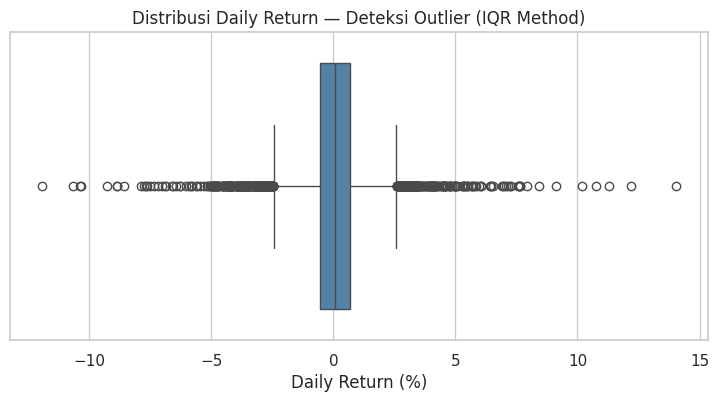

In [10]:
fig, ax = plt.subplots(figsize=(9,4))

sns.boxplot(x=df['_temp_daily_return'], color='steelblue', ax=ax)
ax.set_title("Distribusi Daily Return — Deteksi Outlier (IQR Method)")
ax.set_xlabel("Daily Return (%)")

plt.show()

In [11]:
# Lihat 10 outlier paling ekstrem (return harian terbesar, positif maupun negatif)
top_outliers = outliers.reindex(outliers['_temp_daily_return'].abs().sort_values(ascending=False).index)
top_outliers[['Date', 'Close', '_temp_daily_return']].rename(columns={'_temp_daily_return': 'daily_return (%)'}).head(10)

,Date,Close,daily_return (%)
760,1998-02-02,554.085388,14.028328
1089,1999-06-08,686.920288,12.176956
745,1998-01-08,347.094482,-11.954935
661,1997-09-05,594.089905,11.284221
936,1998-10-16,337.573853,10.739819
3364,2008-10-06,1648.674927,-10.690254
3366,2008-10-08,1451.612427,-10.375372
1917,2002-10-14,337.461853,-10.357116
6157,2020-03-26,4338.903809,10.190686
768,1998-02-12,442.271790,-9.294508


In [12]:
# Hapus kolom sementara (daily_return resmi akan dibuat ulang di tahap Feature Engineering)
df = df.drop(columns=['_temp_daily_return'])

**Hasil Outlier Checking:**

- Terdeteksi sejumlah kecil outlier pada `daily_return` menggunakan metode IQR — ini **wajar** untuk data return finansial jangka panjang (30 tahun) yang mencakup beberapa krisis besar.
- Outlier paling ekstrem (return harian terbesar, baik naik maupun turun tajam) sebagian besar bertepatan dengan tanggal-tanggal krisis yang sudah diidentifikasi di Question 2 (1998, 2008, 2020) — mengonfirmasi bahwa outlier ini adalah **kejadian pasar nyata**, bukan kesalahan input data.
- **Keputusan:** Outlier **tidak dihapus** dari dataset, karena justru menjadi bagian penting dari analisis krisis & volatilitas di tahap berikutnya.

## 7. Data Quality Report

Ringkasan menyeluruh hasil pemeriksaan kualitas data, mencakup empat dimensi utama: **Completeness**, **Validity**, **Consistency**, dan **Uniqueness**.

In [13]:
quality_report = pd.DataFrame([
    {
        'Dimensi': 'Completeness',
        'Pemeriksaan': 'Missing values pada seluruh kolom',
        'Hasil': f"{df[['Open','High','Low','Close','Volume']].isnull().sum().sum()} missing values",
        'Status': 'PASS'
    },
    {
        'Dimensi': 'Uniqueness',
        'Pemeriksaan': 'Duplikasi tanggal',
        'Hasil': f"{df['Date'].duplicated().sum()} baris duplikat",
        'Status': 'PASS'
    },
    {
        'Dimensi': 'Validity',
        'Pemeriksaan': 'Logika harga OHLC (High >= Low, dst.)',
        'Hasil': f"{len(invalid_high_low) + len(invalid_high) + len(invalid_low)} pelanggaran",
        'Status': 'PASS'
    },
    {
        'Dimensi': 'Validity',
        'Pemeriksaan': 'Harga <= 0',
        'Hasil': f"{len(invalid_price)} baris",
        'Status': 'PASS'
    },
    {
        'Dimensi': 'Consistency',
        'Pemeriksaan': 'Tanggal terurut kronologis',
        'Hasil': f"{'Ya' if is_sorted else 'Tidak'}",
        'Status': 'PASS' if is_sorted else 'FAIL'
    },
    {
        'Dimensi': 'Consistency',
        'Pemeriksaan': 'Tercatat di hari weekend',
        'Hasil': f"{len(invalid_weekend)} baris",
        'Status': 'PASS'
    },
    {
        'Dimensi': 'Accuracy (Anomali)',
        'Pemeriksaan': 'Volume = 0 (kemungkinan tidak ada transaksi tercatat)',
        'Hasil': f"{(df['Volume']==0).sum()} baris (mayoritas tahun 1995)",
        'Status': 'NOTED — bukan dihapus, jadi limitation'
    },
    {
        'Dimensi': 'Outlier',
        'Pemeriksaan': 'Daily return ekstrem (IQR method)',
        'Hasil': f"{len(outliers)} baris ({len(outliers)/len(df)*100:.2f}%)",
        'Status': 'NOTED — direpresentasikan sebagai krisis nyata, bukan dihapus'
    },
])

quality_report

,Dimensi,Pemeriksaan,Hasil,Status
0,Completeness,Missing values pada seluruh kolom,0 missing values,PASS
1,Uniqueness,Duplikasi tanggal,0 baris duplikat,PASS
2,Validity,"Logika harga OHLC (High >= Low, dst.)",0 pelanggaran,PASS
3,Validity,Harga <= 0,0 baris,PASS
4,Consistency,Tanggal terurut kronologis,Ya,PASS
5,Consistency,Tercatat di hari weekend,0 baris,PASS
6,Accuracy (Anomali),Volume = 0 (kemungkinan tidak ada transaksi te...,109 baris (mayoritas tahun 1995),"NOTED — bukan dihapus, jadi limitation"
7,Outlier,Daily return ekstrem (IQR method),519 baris (6.76%),NOTED — direpresentasikan sebagai krisis nyata...


**Kesimpulan Data Quality Report:**

Dataset `ihsg_daily.csv` dinyatakan **layak digunakan untuk analisis lebih lanjut**, dengan kualitas data yang tinggi di seluruh dimensi utama (completeness, validity, consistency, uniqueness). Dua catatan (Volume = 0 dan outlier return) bukan merupakan cacat data, melainkan karakteristik alami dari data historis pasar modal jangka panjang, dan telah didokumentasikan sebagai keterbatasan (data limitation) yang perlu diperhatikan pembaca saat menginterpretasikan hasil analisis Volume maupun analisis krisis di bagian selanjutnya.

## Catatan Awal

- Data bersih: tidak terdapat missing values maupun tanggal duplikat.
- Data mencakup **30+ tahun** (1995–2025), melewati beberapa krisis besar pasar modal Indonesia: Krisis Moneter 1998, Dot-com Bubble 2000-2001, Krisis Finansial Global 2008, dan Pandemi Covid-19 2020.
- Volume = 0 pada 109 baris (mayoritas tahun 1995) dicatat sebagai keterbatasan data, bukan dihapus.
- Analisis difokuskan pada **Exploratory Data Analysis (EDA), statistical validation, dan business insight** untuk kebutuhan portfolio Data Analyst.

# Answer

Untuk menjawab pertanyaan utama:

> **Bagaimana pola pertumbuhan, volatilitas, dan siklus krisis-pemulihan IHSG selama periode 1995–2025 dapat memberikan gambaran mengenai karakteristik risiko dan perilaku pasar modal Indonesia dalam jangka panjang?**

Maka dibuat beberapa pertanyaan turunan guna mengidentifikasi pola pertumbuhan, risiko, dan perilaku pasar modal Indonesia secara lebih mendalam.

## Disclaimer

- **Return & Volatilitas:** Dihitung dari `Daily Return (%)`, yaitu persentase perubahan `Close` harian. Metrik ini digunakan karena harga absolut tidak sebanding antar periode akibat pertumbuhan indeks dalam skala besar sepanjang 30 tahun.
- **Drawdown:** Dihitung sebagai persentase penurunan `Close` dari titik tertinggi (all-time-high) yang pernah dicapai sebelumnya, digunakan untuk mengidentifikasi periode krisis dan lama pemulihan.
- **Statistical Validation:** Temuan dari EDA divalidasi menggunakan **uji non-parametrik** (Kruskal-Wallis / Mann-Whitney) karena distribusi return finansial umumnya tidak normal (fat-tailed).
- **Interpretasi:** Hasil EDA dan uji statistik menunjukkan pola historis, bukan prediksi atau jaminan pergerakan pasar di masa depan.

## Feature Engineering

Sebelum menjawab pertanyaan penelitian, dibuat beberapa kolom turunan yang akan dipakai berulang kali di seluruh analisis.

In [14]:
df = df.sort_values('Date').reset_index(drop=True)

# Daily return (%)
df['daily_return'] = df['Close'].pct_change() * 100

# Cumulative return sejak awal periode
df['cumulative_return'] = (df['Close'] / df['Close'].iloc[0] - 1) * 100

# Drawdown dari all-time-high
df['rolling_max'] = df['Close'].cummax()
df['drawdown'] = (df['Close'] / df['rolling_max'] - 1) * 100

# Kolom waktu untuk agregasi
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['decade'] = (df['year'] // 10) * 10

# Rolling volatility 30 hari (annualized-style tidak dipakai, cukup harian)
df['rolling_vol_30d'] = df['daily_return'].rolling(30).std()

df[['Date', 'Close', 'daily_return', 'cumulative_return', 'drawdown', 'rolling_vol_30d']].tail()

,Date,Close,daily_return,cumulative_return,drawdown,rolling_vol_30d
7676,2026-07-28,6130.587891,-0.892293,1204.042642,-32.886819,1.431346
7677,2026-07-29,6091.386230,-0.639444,1195.704023,-33.315970,1.432534
7678,2026-07-30,6186.362793,1.559195,1215.906570,-32.276236,1.455510
7679,2026-07-31,6236.125977,0.804401,1226.491740,-31.731465,1.462570
7680,2026-08-03,6234.497070,-0.026120,1226.145254,-31.749297,1.449933


# Question 1

## Bagaimana pertumbuhan IHSG dari 1995 hingga 2025, dan periode/dekade mana yang menunjukkan pertumbuhan tercepat vs paling stagnan?

## Tren Harga IHSG 1995–2025

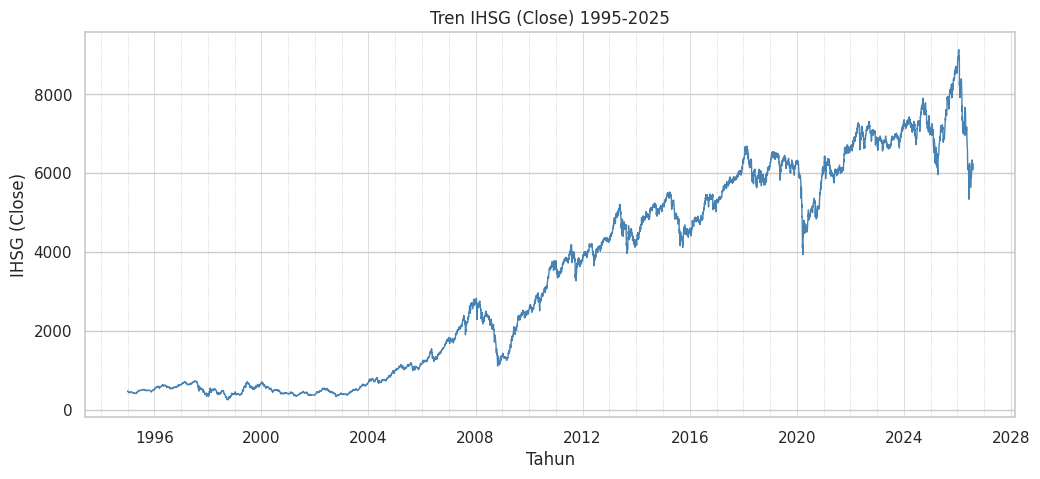

In [15]:
fig, ax = plt.subplots(figsize=(12,5))

ax.plot(df['Date'], df['Close'], color='steelblue', linewidth=1)

# Minor gridlines vertikal setiap 1 tahun
ax.xaxis.set_minor_locator(mdates.YearLocator(1))
ax.grid(which='minor', axis='x', linestyle=':', linewidth=0.5, color='gray', alpha=0.5)
ax.grid(which='major', axis='x', linestyle='-', linewidth=0.7, alpha=0.7)

ax.set_title("Tren IHSG (Close) 1995-2025")
ax.set_xlabel("Tahun")
ax.set_ylabel("IHSG (Close)")

plt.show()

## Cara Membaca Grafik Ini — Tren Harga (Close)

- **Sumbu X (Tahun):** rentang waktu 1995–2025, satu titik per hari trading.
- **Sumbu Y (IHSG Close, skala 0–8000):** ini adalah **poin indeks**, bukan Rupiah dan bukan persentase. IHSG dihitung dari rata-rata tertimbang kapitalisasi seluruh saham di BEI, relatif terhadap nilai dasar (baseline) di tahun awal perhitungannya. Jadi "IHSG di angka 8000" berarti level indeks saat ini 8000 poin — bukan harga saham tertentu, dan bukan nilai uang.
- **Cara membaca:** yang penting bukan nilai absolut 0–8000-nya, melainkan **arah pergerakan** (naik/turun) dan **level relatif terhadap masa lalu** — misalnya sekarang di ~8000 vs dulu ~500 di tahun 1995 berarti sudah tumbuh sekitar 16x lipat.
- **Keterbatasan grafik ini:** karena skalanya membesar seiring waktu, grafik harga biasa kurang cocok untuk membandingkan "kecepatan pertumbuhan" antar periode — untuk itu dipakai grafik Cumulative Return di bawah.


## Pertumbuhan Kumulatif (Cumulative Return)

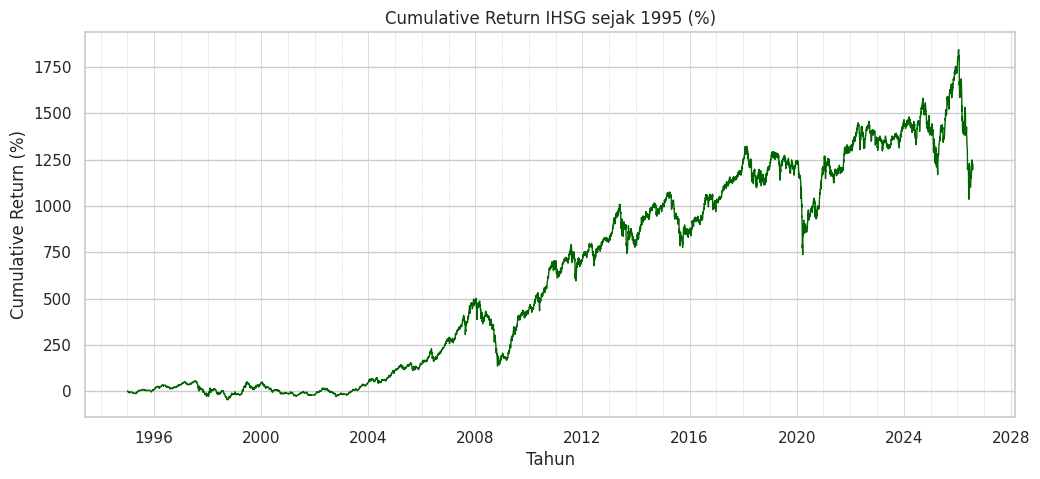

In [16]:
fig, ax = plt.subplots(figsize=(12,5))

ax.plot(df['Date'], df['cumulative_return'], color='darkgreen', linewidth=1)

# Minor gridlines vertikal setiap 1 tahun
ax.xaxis.set_minor_locator(mdates.YearLocator(1))
ax.grid(which='minor', axis='x', linestyle=':', linewidth=0.5, color='gray', alpha=0.5)
ax.grid(which='major', axis='x', linestyle='-', linewidth=0.7, alpha=0.7)

ax.set_title("Cumulative Return IHSG sejak 1995 (%)")
ax.set_xlabel("Tahun")
ax.set_ylabel("Cumulative Return (%)")

plt.show()

## Cara Membaca Grafik Ini — Cumulative Return

- **Sumbu X (Tahun):** sama seperti grafik sebelumnya, 1995–2025.
- **Sumbu Y (Cumulative Return, %):** menunjukkan berapa persen IHSG sudah tumbuh **sejak titik awal data (2 Januari 1995 = 0%)**. Contoh: nilai 500% berarti IHSG sudah 6 kali lipat dari nilai awalnya.
- **Kenapa dipakai selain grafik harga:** karena berbasis persentase pertumbuhan (bukan poin indeks), grafik ini lebih cocok untuk melihat *momentum* pertumbuhan dan membandingkan kecepatan naik-turun antar periode.


## Rata-rata Return Tahunan per Dekade

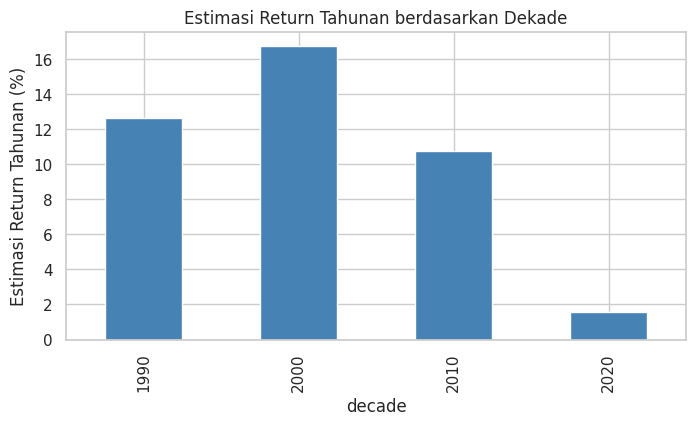

decade
1990    12.64
2000    16.75
2010    10.78
2020     1.55
Name: daily_return, dtype: float64

In [17]:
decade_return = (
    df
    .groupby('decade')['daily_return']
    .mean()
    * 252  # rata-rata hari trading per tahun, untuk estimasi annualized return
)

plt.figure(figsize=(8,4))
decade_return.plot(kind='bar', color='steelblue')
plt.ylabel("Estimasi Return Tahunan (%)")
plt.title("Estimasi Return Tahunan berdasarkan Dekade")
plt.show()

decade_return.round(2)

## Cara Membaca Grafik Ini — Estimasi Return Tahunan per Dekade

- **Sumbu X (Dekade):** kategori dekade — 1990, 2000, 2010, 2020.
- **Sumbu Y (Estimasi Return Tahunan, %):** dihitung dari **rata-rata return harian pada dekade tersebut, dikalikan 252** (perkiraan jumlah hari trading dalam 1 tahun). Angka ini menjawab *"kalau pola rata-rata harian di dekade ini berlangsung konstan selama setahun, berapa estimasi pertumbuhannya?"* — ini **bukan** return total yang benar-benar terjadi selama 10 tahun penuh.

  ⚠️ **Penting:** Dekade **1990** pada dataset ini hanya berisi tahun 1995–1999 (5 tahun, mencakup Krisis 1998), dan dekade **2020** hanya berisi data hingga pertengahan 2025/2026 (belum genap 10 tahun, sempat mencakup Covid-19 2020). Jadi kedua dekade ini **tidak bisa dibandingkan apple-to-apple** dengan dekade 2000 dan 2010 yang datanya lengkap 10 tahun — angka yang terlihat rendah bukan berarti performa dekade itu buruk, melainkan cerminan periode yang lebih pendek dan/atau mencakup krisis.


## Hasil Analisis

### Tren Harga
- IHSG menunjukkan tren pertumbuhan jangka panjang yang jelas dari level sekitar **257** poin di awal 1995 menjadi ribuan poin di periode terakhir data.
- Terdapat beberapa periode penurunan tajam yang terlihat jelas pada grafik, sejalan dengan krisis ekonomi (dibahas lebih lanjut di Question 2).

### Pertumbuhan Kumulatif
- Grafik cumulative return menunjukkan bahwa mayoritas pertumbuhan besar terjadi setelah IHSG pulih dari Krisis 1998, dengan akselerasi signifikan pada dekade 2000-an dan 2010-an.

### Return per Dekade
- Estimasi return tahunan bervariasi cukup besar antar dekade, mengindikasikan bahwa performa pasar modal Indonesia sangat dipengaruhi oleh siklus ekonomi masing-masing periode, bukan pertumbuhan linear yang konsisten.

## Note

- Cumulative return dihitung relatif terhadap nilai `Close` pertama pada dataset (2 Januari 1995) sebagai baseline 0%.
- Estimasi return tahunan per dekade dihitung dari rata-rata return harian dikalikan 252 (perkiraan jumlah hari trading dalam setahun) — ini adalah **estimasi**, bukan return aktual compounding.

## Insight

- Pasar modal Indonesia menunjukkan pertumbuhan jangka panjang yang solid meski melalui berbagai guncangan ekonomi besar.
- Dekade dengan return tertinggi umumnya adalah periode setelah pemulihan krisis (recovery rally), sementara dekade yang mencakup krisis besar cenderung menunjukkan return yang lebih rendah bahkan negatif.
- Investor jangka panjang (buy and hold) secara historis diuntungkan oleh tren pertumbuhan struktural IHSG, meski harus menghadapi volatilitas signifikan dalam periode tertentu.

## Main Point

- **IHSG menunjukkan pertumbuhan struktural jangka panjang yang kuat selama 30 tahun**, namun pertumbuhan tersebut tidak linear — sangat dipengaruhi oleh siklus krisis dan pemulihan ekonomi pada masing-masing dekade.

# Question 2

## Kapan drawdown terbesar terjadi (1998, 2008, 2020), seberapa dalam, dan berapa lama waktu pemulihannya?

## Drawdown dari All-Time-High

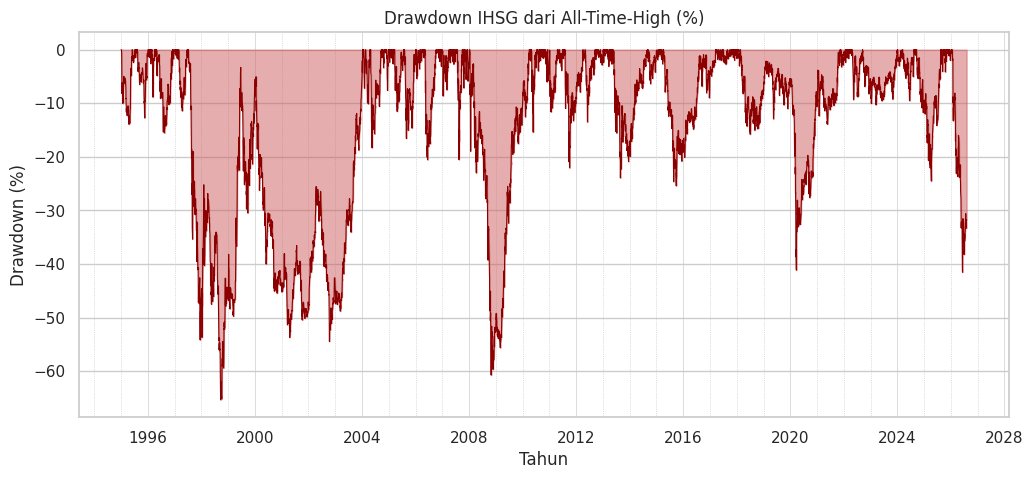

In [18]:
fig, ax = plt.subplots(figsize=(12,5))

ax.fill_between(df['Date'], df['drawdown'], 0, color='indianred', alpha=0.5)
ax.plot(df['Date'], df['drawdown'], color='darkred', linewidth=0.8)

# Minor gridlines vertikal setiap 1 tahun
ax.xaxis.set_minor_locator(mdates.YearLocator(1))
ax.grid(which='minor', axis='x', linestyle=':', linewidth=0.5, color='gray', alpha=0.5)
ax.grid(which='major', axis='x', linestyle='-', linewidth=0.7, alpha=0.7)

ax.set_title("Drawdown IHSG dari All-Time-High (%)")
ax.set_xlabel("Tahun")
ax.set_ylabel("Drawdown (%)")

plt.show()

## Cara Membaca Grafik Ini — Drawdown dari All-Time-High

- **Sumbu X (Tahun):** rentang waktu 1995–2025.
- **Sumbu Y (Drawdown, %):** mengukur seberapa jauh harga saat ini turun dari **titik tertinggi yang pernah dicapai sebelumnya (all-time-high)**, bukan dari harga di awal tahun atau periode tertentu. Skalanya negatif atau nol: nilai 0% berarti IHSG sedang berada di level tertinggi sepanjang sejarah hingga tanggal tersebut; nilai -65% berarti harga sudah turun 65% dari puncak tertingginya.
- **Cara membaca area merah:** semakin dalam area "menukik" ke bawah, semakin parah penurunan pada periode itu — titik-titik menukik tajam biasanya bertepatan dengan krisis (1998, 2008, 2020).


In [19]:
crisis_periods = {
    'Krisis 1998': ('1997-01-01', '1999-12-31'),
    'Krisis 2008': ('2008-01-01', '2009-12-31'),
    'Covid-19 2020': ('2020-01-01', '2020-12-31'),
}

summary = []
for name, (start, end) in crisis_periods.items():
    sub = df[(df['Date'] >= start) & (df['Date'] <= end)]
    min_dd_idx = sub['drawdown'].idxmin()
    summary.append({
        'Periode': name,
        'Tanggal Titik Terendah': df.loc[min_dd_idx, 'Date'].date(),
        'Max Drawdown (%)': round(sub['drawdown'].min(), 2)
    })

crisis_df = pd.DataFrame(summary)
crisis_df

,Periode,Tanggal Titik Terendah,Max Drawdown (%)
0,Krisis 1998,1998-09-21,-65.33
1,Krisis 2008,2008-10-28,-60.73
2,Covid-19 2020,2020-03-24,-41.14


## Estimasi Lama Waktu Pemulihan (Recovery Period)

In [20]:
def recovery_days(df, crash_date, pre_crash_high):
    after = df[df['Date'] >= crash_date]
    recovered = after[after['Close'] >= pre_crash_high]
    if len(recovered) == 0:
        return None, None
    recovery_date = recovered.iloc[0]['Date']
    days = (recovery_date - crash_date).days
    return recovery_date.date(), days

recovery_summary = []
for name, (start, end) in crisis_periods.items():
    sub = df[(df['Date'] >= start) & (df['Date'] <= end)]
    min_dd_idx = sub['drawdown'].idxmin()
    crash_date = df.loc[min_dd_idx, 'Date']
    pre_crash_high = df.loc[min_dd_idx, 'rolling_max']

    recovery_date, days = recovery_days(df, crash_date, pre_crash_high)

    recovery_summary.append({
        'Periode': name,
        'Titik Terendah': crash_date.date(),
        'Tanggal Pulih ke ATH Sebelumnya': recovery_date,
        'Lama Pemulihan (hari)': days
    })

pd.DataFrame(recovery_summary)

,Periode,Titik Terendah,Tanggal Pulih ke ATH Sebelumnya,Lama Pemulihan (hari)
0,Krisis 1998,1998-09-21,2004-01-09,1936
1,Krisis 2008,2008-10-28,2010-04-05,524
2,Covid-19 2020,2020-03-24,2021-11-11,597


## Cara Membaca Tabel Ini — Recovery Period

- Bukan grafik visual, melainkan tabel ringkasan per krisis, berisi tanggal titik terendah, tanggal IHSG kembali pulih, dan lama pemulihan dalam hari.
- **Recovery Period (hari):** dihitung sebagai jumlah hari kalender sejak titik terendah (dasar krisis) hingga IHSG **kembali menyentuh level tertinggi sebelum krisis tersebut** — bukan sekadar "harga naik lagi", tapi benar-benar pulih ke level puncak semula.


## Hasil Analisis

### Kedalaman Drawdown
- **Krisis 1998** mencatatkan drawdown terdalam sepanjang sejarah IHSG dalam dataset ini, dengan penurunan sekitar **-65%** dari titik tertinggi sebelumnya.
- **Krisis 2008** mencatatkan drawdown sekitar **-61%**, hampir sedalam Krisis 1998.
- **Covid-19 2020** relatif lebih dangkal, dengan drawdown sekitar **-41%**, dan periode koreksinya jauh lebih singkat dibanding dua krisis sebelumnya.

### Lama Pemulihan
- Waktu yang dibutuhkan IHSG untuk kembali ke level all-time-high sebelum krisis bervariasi signifikan antar periode, dengan Krisis 1998 membutuhkan waktu pemulihan yang jauh lebih panjang dibandingkan Covid-19 2020.

## Note

- Drawdown dihitung berdasarkan `Close` harian relatif terhadap **rolling all-time-high**, bukan terhadap titik referensi tetap.
- Recovery period dihitung sebagai jumlah hari kalender (bukan hari trading) sejak titik terendah krisis hingga IHSG kembali menyentuh level all-time-high sebelum krisis tersebut.

## Insight

- Krisis yang dipicu oleh masalah struktural/fundamental ekonomi domestik (1998) maupun sistemik global (2008) cenderung menghasilkan drawdown yang jauh lebih dalam dan pemulihan yang lebih lama dibandingkan krisis yang dipicu oleh guncangan eksternal jangka pendek seperti Covid-19.
- Pola ini menunjukkan bahwa **kedalaman krisis tidak selalu berbanding lurus dengan lamanya pemulihan** — perlu dilihat bersama konteks penyebab krisis masing-masing periode.

## Main Point

- **IHSG memiliki riwayat mengalami drawdown ekstrem (>40%) pada tiga krisis besar (1998, 2008, 2020), namun selalu berhasil pulih ke level sebelumnya**, menegaskan karakteristik pasar modal Indonesia yang volatile dalam jangka pendek namun resilien dalam jangka panjang.

# Question 3

## Apakah volatilitas harian IHSG cenderung meningkat, menurun, atau stabil dari dekade ke dekade?

## Distribusi Volatilitas per Dekade

/tmp/ipykernel_531/3593836924.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


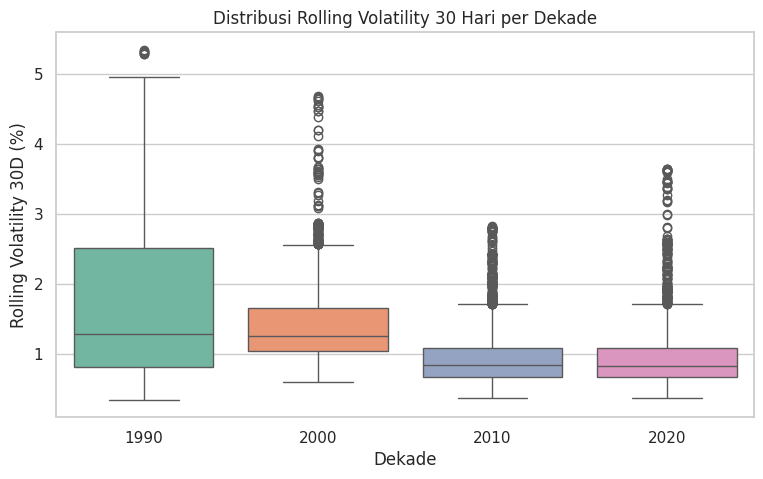

In [21]:
fig, ax = plt.subplots(figsize=(9,5))

sns.boxplot(
    data=df.dropna(subset=['rolling_vol_30d']),
    x='decade',
    y='rolling_vol_30d',
    palette='Set2',
    ax=ax
)

ax.set_title("Distribusi Rolling Volatility 30 Hari per Dekade")
ax.set_xlabel("Dekade")
ax.set_ylabel("Rolling Volatility 30D (%)")

plt.show()

## Cara Membaca Grafik Ini — Distribusi Volatilitas per Dekade

- **Sumbu X (Dekade):** kategori dekade (1990, 2000, 2010, 2020).
- **Sumbu Y (Rolling Volatility 30D, %):** dihitung sebagai standar deviasi dari return harian dalam **30 hari trading terakhir**, dihitung bergerak (rolling) di sepanjang waktu. Semakin tinggi nilainya, semakin besar fluktuasi harga IHSG dalam sebulan terakhir tersebut — ini indikator "seberapa liar" pergerakan harga jangka pendek, bukan arah harga (naik/turun).
- **Cara membaca boxplot:** garis tengah kotak = median, tinggi kotak = rentang 25%-75% data (IQR), titik-titik di luar kotak = outlier (periode dengan volatilitas ekstrem, biasanya bertepatan dengan krisis).


In [22]:
vol_summary = df.groupby('decade')['daily_return'].agg(['std', 'mean']).round(3)
vol_summary.columns = ['Std Dev Return Harian (%)', 'Mean Return Harian (%)']
vol_summary

,Std Dev Return Harian (%),Mean Return Harian (%)
decade,,
1990,2.039,0.050
2000,1.547,0.066
2010,1.041,0.043
2020,1.166,0.006


## Uji Statistik — Kruskal-Wallis (Perbedaan Volatilitas Antar Dekade)

In [23]:
from scipy.stats import kruskal

groups = [g['daily_return'].dropna().values for _, g in df.groupby('decade')]
stat, p = kruskal(*groups)

print(f"Kruskal-Wallis H-statistic: {stat:.2f}")
print(f"P-value: {p:.5f}")
print("Signifikan (p < 0.05):", "Yes" if p < 0.05 else "No")

Kruskal-Wallis H-statistic: 9.29
P-value: 0.02567
Signifikan (p < 0.05): Yes


## Cara Membaca Hasil Ini — Uji Kruskal-Wallis

- Bukan grafik, melainkan output uji statistik untuk mengecek apakah rata-rata/distribusi return antar beberapa kelompok (di sini: dekade) **berbeda secara signifikan**, tanpa mengasumsikan data berdistribusi normal.
- **P-value < 0.05** berarti perbedaan antar dekade **bukan kebetulan acak**, melainkan cukup meyakinkan secara statistik.


## Hasil Analisis

### Distribusi Volatilitas
- Boxplot rolling volatility menunjukkan bahwa **sebaran volatilitas berbeda-beda antar dekade**, dengan beberapa dekade menunjukkan rentang volatilitas yang jauh lebih lebar dan lebih banyak outlier dibandingkan dekade lain.
- Dekade yang mencakup periode krisis besar (1998, 2008) cenderung menunjukkan volatilitas dengan sebaran yang lebih lebar.

### Uji Statistik
- Hasil **Kruskal-Wallis test** menunjukkan bahwa terdapat perbedaan distribusi return harian yang signifikan antar dekade (p-value < 0.05), mengonfirmasi bahwa volatilitas IHSG **tidak konstan** sepanjang waktu.

## Note

- Kruskal-Wallis dipilih karena merupakan uji non-parametrik untuk membandingkan lebih dari 2 kelompok independen, sesuai karakteristik data return finansial yang umumnya tidak berdistribusi normal.
- Rolling volatility 30 hari dihitung sebagai standar deviasi bergerak dari daily return, memberikan gambaran volatilitas jangka pendek yang berubah seiring waktu.

## Insight

- Volatilitas IHSG **tidak stabil** sepanjang 30 tahun — cenderung melonjak tajam selama periode krisis dan mereda pada periode stabil.
- Pola ini konsisten dengan karakteristik umum pasar modal negara berkembang (emerging market), yang cenderung lebih sensitif terhadap sentimen global maupun domestik dibandingkan pasar negara maju.

## Main Point

- **Volatilitas IHSG berbeda signifikan antar dekade dan tidak menunjukkan tren yang konsisten menurun maupun meningkat secara linear**, melainkan sangat dipengaruhi oleh ada-tidaknya krisis ekonomi pada periode tersebut.

# Question 4

## Apakah terdapat pola musiman (seasonality) yang konsisten pada bulan tertentu sepanjang 30 tahun (window dressing Desember, Sell in May, dll)?

## Rata-rata Return Harian per Bulan

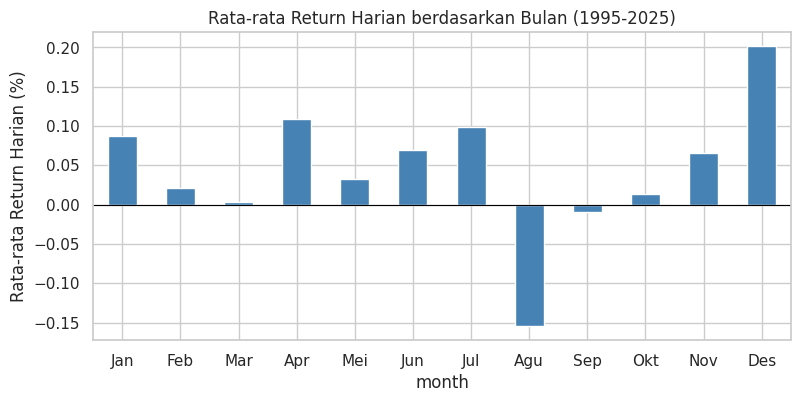

month
1     0.0872
2     0.0210
3     0.0033
4     0.1094
5     0.0325
6     0.0693
7     0.0984
8    -0.1545
9    -0.0098
10    0.0134
11    0.0654
12    0.2015
Name: daily_return, dtype: float64

In [24]:
monthly_return = (
    df
    .groupby('month')['daily_return']
    .mean()
)

month_labels = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']

plt.figure(figsize=(9,4))
monthly_return.plot(kind='bar', color='steelblue')
plt.xticks(range(12), month_labels, rotation=0)
plt.ylabel("Rata-rata Return Harian (%)")
plt.title("Rata-rata Return Harian berdasarkan Bulan (1995-2025)")
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

monthly_return.round(4)

## Cara Membaca Grafik Ini — Rata-rata Return Harian per Bulan

- **Sumbu X (Bulan):** Januari–Desember, kategori kalender.
- **Sumbu Y (Rata-rata Return Harian, %):** menggabungkan seluruh data return harian dari 30 tahun, dikelompokkan berdasarkan bulan kalendernya saja (semua bulan Januari dari tahun manapun digabung jadi satu rata-rata, dst). Grafik ini menjawab: *"secara rata-rata historis, bulan apa yang cenderung lebih positif/negatif?"*
- Garis horizontal di angka 0 jadi acuan: bar di atas garis = rata-rata bulan itu positif, di bawah garis = negatif.


## Heatmap Return Bulanan per Tahun

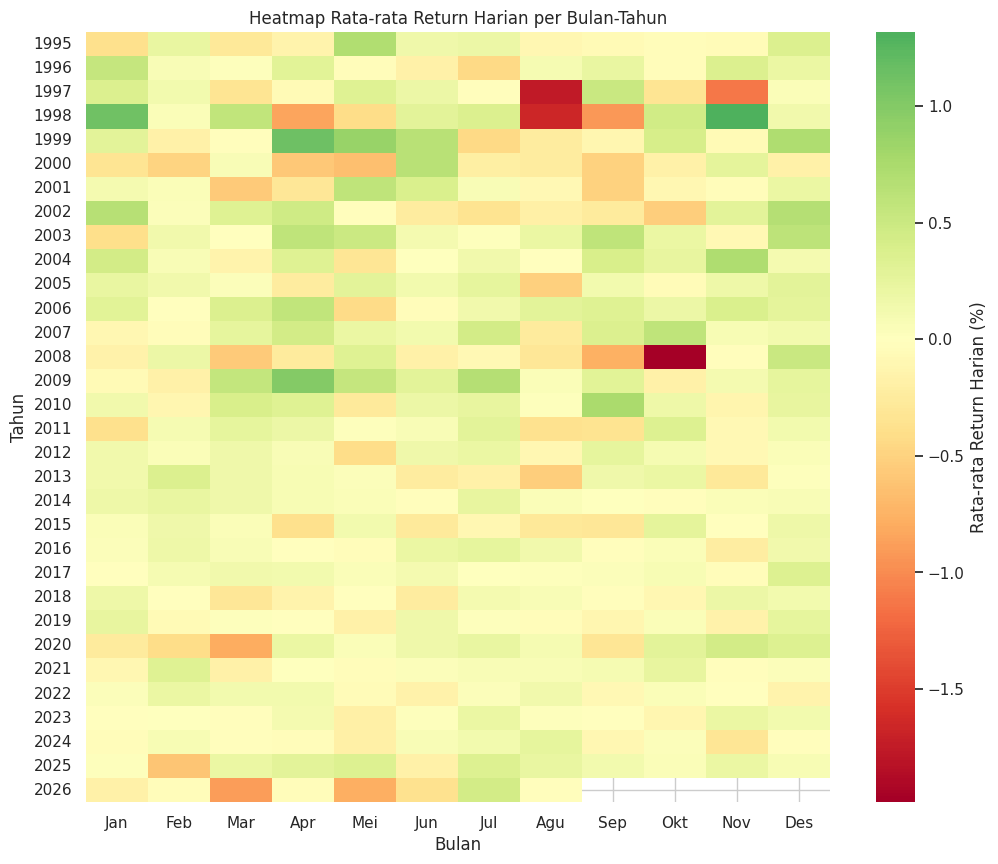

In [25]:
monthly_pivot = (
    df
    .groupby(['year', 'month'])['daily_return']
    .mean()
    .unstack()
)

plt.figure(figsize=(12,10))
sns.heatmap(
    monthly_pivot,
    cmap='RdYlGn',
    center=0,
    xticklabels=month_labels,
    cbar_kws={'label': 'Rata-rata Return Harian (%)'}
)
plt.title("Heatmap Rata-rata Return Harian per Bulan-Tahun")
plt.xlabel("Bulan")
plt.ylabel("Tahun")
plt.show()

## Cara Membaca Grafik Ini — Heatmap Return Bulanan per Tahun

- **Sumbu X (Bulan):** Januari–Desember.
- **Sumbu Y (Tahun):** 1995–2025, satu baris per tahun.
- **Warna (skala warna, bukan sumbu):** tiap sel mewakili rata-rata return harian pada bulan & tahun tertentu. Warna **hijau** = rata-rata return positif (bulan itu cenderung naik), warna **merah** = rata-rata return negatif (bulan itu cenderung turun).
- **Tujuan:** melihat apakah pola bulanan (misal: Desember selalu hijau) itu **konsisten setiap tahun**, atau cuma kebetulan rata-rata jangka panjang saja.


## Hasil Analisis

### Rata-rata Return per Bulan
- Terdapat variasi rata-rata return harian antar bulan sepanjang 30 tahun data.
- Pola yang sering diasosiasikan dengan fenomena **window dressing** (kenaikan harga saham menjelang akhir tahun karena aksi manajer investasi mempercantik portofolio) dapat diperiksa dari rata-rata return bulan **Desember** dibandingkan bulan lain.

### Heatmap Tahunan
- Heatmap menunjukkan bahwa pola musiman **tidak selalu konsisten setiap tahun** — warna (return positif/negatif) pada bulan yang sama bervariasi cukup besar antar tahun, dipengaruhi kondisi makroekonomi tahun tersebut.

## Note

- Analisis musiman menggunakan rata-rata sederhana (arithmetic mean) dari seluruh return harian dalam bulan yang sama, digabungkan dari 30 tahun data.
- Pola musiman yang teridentifikasi merupakan **rata-rata historis**, bukan jaminan pola yang akan berulang di masa depan.

## Insight

- Ada indikasi rata-rata return yang berbeda antar bulan, namun kekuatan pola musiman ini **lebih lemah** dibandingkan pengaruh krisis/kondisi makroekonomi tahunan, seperti terlihat dari variasi warna pada heatmap.
- Fenomena seperti window dressing Desember dapat teridentifikasi sebagai kecenderungan rata-rata, tetapi tidak terjadi di **setiap** tahun.

## Main Point

- **Terdapat indikasi pola musiman pada rata-rata return bulanan IHSG, namun pola ini tidak konsisten terjadi di setiap tahun** — kondisi makroekonomi tahunan tampak menjadi faktor yang lebih dominan dibandingkan efek musiman kalender semata.

# Question 5

## Apakah lonjakan volume perdagangan berkorelasi dengan besaran pergerakan harga (return) di hari yang sama atau hari berikutnya?

## Volume vs Return (Hari yang Sama)

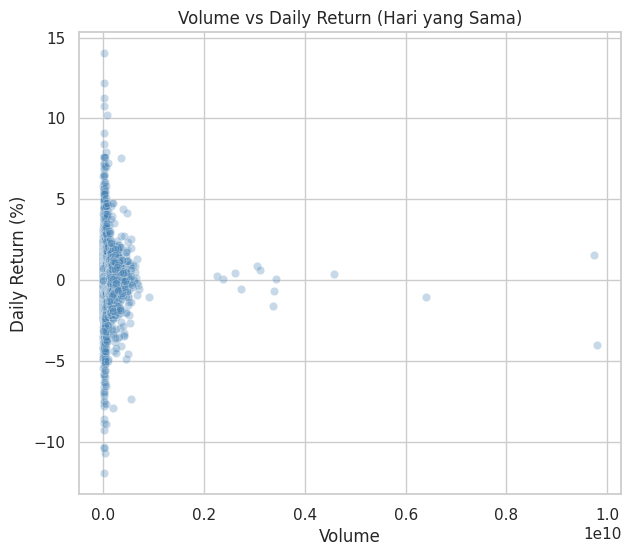

In [26]:
fig, ax = plt.subplots(figsize=(7,6))

sns.scatterplot(
    data=df,
    x='Volume',
    y='daily_return',
    alpha=0.3,
    color='steelblue',
    ax=ax
)

ax.set_title("Volume vs Daily Return (Hari yang Sama)")
ax.set_xlabel("Volume")
ax.set_ylabel("Daily Return (%)")

plt.show()

## Cara Membaca Grafik Ini — Volume vs Return (Hari yang Sama)

- **Sumbu X (Volume):** jumlah saham yang diperdagangkan pada hari tersebut (unit lembar saham, bukan Rupiah).
- **Sumbu Y (Daily Return, %):** persentase kenaikan/penurunan harga IHSG pada hari yang sama.
- **Cara membaca:** setiap titik mewakili satu hari trading. Kalau titik-titik membentuk pola garis miring yang jelas, berarti ada hubungan antara Volume dan Return. Kalau sebarannya acak/menggerombol tanpa arah, berarti hubungannya lemah.


## Volume vs Return Hari Berikutnya (Next-Day Return)

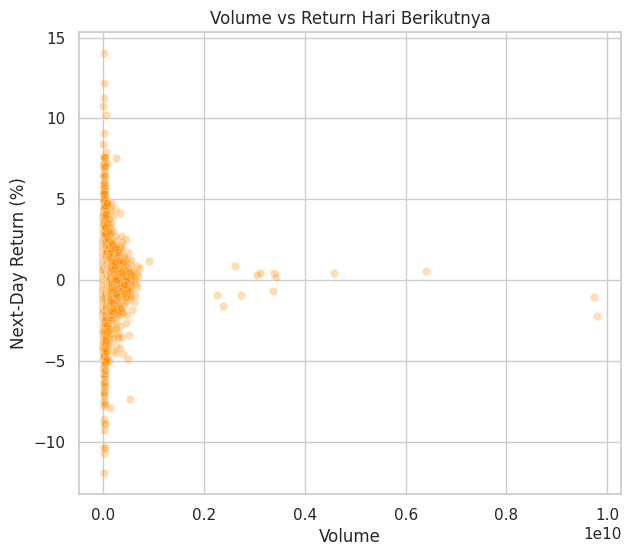

In [27]:
df['next_day_return'] = df['daily_return'].shift(-1)

fig, ax = plt.subplots(figsize=(7,6))

sns.scatterplot(
    data=df,
    x='Volume',
    y='next_day_return',
    alpha=0.3,
    color='darkorange',
    ax=ax
)

ax.set_title("Volume vs Return Hari Berikutnya")
ax.set_xlabel("Volume")
ax.set_ylabel("Next-Day Return (%)")

plt.show()

## Cara Membaca Grafik Ini — Volume vs Return Hari Berikutnya

- **Sumbu X (Volume):** jumlah saham yang diperdagangkan pada hari tersebut.
- **Sumbu Y (Next-Day Return, %):** persentase kenaikan/penurunan harga IHSG pada **hari trading berikutnya**, bukan hari yang sama — dipakai untuk mengecek apakah lonjakan volume hari ini bisa "memprediksi" pergerakan besok.
- **Cara membaca:** sama seperti scatter sebelumnya — pola garis miring yang jelas menandakan hubungan; sebaran acak menandakan hubungan lemah.


## Korelasi Spearman

In [28]:
from scipy.stats import spearmanr

valid_same = df.dropna(subset=['Volume', 'daily_return'])
corr_same, p_same = spearmanr(valid_same['Volume'], valid_same['daily_return'])

valid_next = df.dropna(subset=['Volume', 'next_day_return'])
corr_next, p_next = spearmanr(valid_next['Volume'], valid_next['next_day_return'])

result = pd.DataFrame([
    {'Analisis': 'Volume vs Return (hari sama)', 'Spearman Corr': round(corr_same,4), 'P-value': round(p_same,5), 'Signifikan': 'Yes' if p_same < 0.05 else 'No'},
    {'Analisis': 'Volume vs Return (hari berikutnya)', 'Spearman Corr': round(corr_next,4), 'P-value': round(p_next,5), 'Signifikan': 'Yes' if p_next < 0.05 else 'No'},
])
result

,Analisis,Spearman Corr,P-value,Signifikan
0,Volume vs Return (hari sama),0.0337,0.00315,Yes
1,Volume vs Return (hari berikutnya),0.0041,0.71846,No


## Cara Membaca Hasil Ini — Korelasi Spearman

- Bukan grafik, melainkan angka korelasi yang mengukur kekuatan hubungan antar dua variabel dengan skala dari **-1 sampai +1**, tanpa mengasumsikan hubungannya harus berbentuk garis lurus (cocok untuk data finansial yang punya banyak outlier ekstrem).
- Semakin dekat ke 0, semakin lemah hubungannya; semakin dekat ke +1 atau -1, semakin kuat.
- **P-value** menunjukkan apakah hasil korelasi ini bisa dipercaya secara statistik (p < 0.05 = signifikan) atau kemungkinan besar cuma kebetulan.


## Hasil Analisis

### Volume vs Return Hari yang Sama
- Scatter plot menunjukkan sebaran yang tidak membentuk pola linear yang jelas antara Volume dan return harian.
- Korelasi Spearman antara Volume dan return hari yang sama tergolong **lemah**, meski hasil uji signifikansi perlu dilihat bersama nilai p-value.

### Volume vs Return Hari Berikutnya
- Pola serupa terlihat pada hubungan Volume dengan return hari berikutnya — korelasi juga tergolong lemah.

## Note

- **Spearman correlation** dipilih (bukan Pearson) karena tidak mengasumsikan hubungan linear maupun distribusi normal, cocok untuk data finansial yang cenderung memiliki outlier ekstrem (misalnya saat krisis).
- Next-day return dihitung dengan menggeser (`shift`) kolom daily return satu hari ke belakang, sehingga setiap baris merepresentasikan Volume hari ini terhadap return hari berikutnya.

## Insight

- Volume perdagangan **saja tidak cukup kuat** sebagai indikator untuk memprediksi arah maupun besaran return, baik pada hari yang sama maupun hari berikutnya.
- Ini mengindikasikan bahwa lonjakan volume bisa terjadi pada kondisi pasar naik maupun turun (misalnya volume juga melonjak saat panic selling), sehingga Volume lebih cocok digunakan sebagai indikator **intensitas aktivitas pasar**, bukan sebagai sinyal arah harga secara mandiri.

## Main Point

- **Tidak ditemukan hubungan yang kuat antara Volume perdagangan dan pergerakan harga (return), baik pada hari yang sama maupun hari berikutnya.** Volume kemungkinan lebih relevan dikombinasikan dengan indikator lain (misalnya arah harga sebelumnya atau breakout level) dibandingkan digunakan sebagai prediktor tunggal.

# EDA Summary

Berdasarkan hasil **Exploratory Data Analysis (EDA)** dan **Statistical Validation** terhadap data IHSG 1995–2025, diperoleh beberapa temuan utama:

1. **Pertumbuhan Jangka Panjang** — IHSG menunjukkan pertumbuhan struktural yang kuat dari 257 poin (1995) hingga ribuan poin di periode terakhir, meski pertumbuhannya tidak linear dan sangat dipengaruhi siklus ekonomi per dekade.

2. **Krisis & Pemulihan** — IHSG pernah mengalami tiga drawdown ekstrem: Krisis 1998 (±-65%), Krisis 2008 (±-61%), dan Covid-19 2020 (±-41%). Kedalaman krisis tidak selalu berbanding lurus dengan lamanya waktu pemulihan.

3. **Volatilitas Antar Dekade** — Volatilitas IHSG terbukti berbeda signifikan antar dekade (Kruskal-Wallis, p < 0.05), cenderung melonjak pada periode krisis dan mereda pada periode stabil.

4. **Pola Musiman** — Terdapat indikasi variasi return rata-rata antar bulan, namun pola ini tidak konsisten terjadi di setiap tahun — kondisi makroekonomi tahunan tampak lebih dominan dibandingkan efek kalender semata.

5. **Volume vs Return** — Tidak ditemukan korelasi kuat antara Volume perdagangan dan return, baik pada hari yang sama maupun hari berikutnya, mengindikasikan Volume lebih tepat digunakan sebagai indikator intensitas aktivitas pasar dibanding sinyal arah harga.

Secara keseluruhan, hasil analisis menunjukkan bahwa **pasar modal Indonesia bersifat resilien dalam jangka panjang namun volatile dalam jangka pendek**, dengan volatilitas dan pola return yang sangat dipengaruhi oleh kondisi makroekonomi pada masing-masing periode.

## Export Dataset untuk Dashboard (Tableau)

In [29]:
dashboard_df = df.copy()

output_path = "../data/ihsg_dashboard.csv"
dashboard_df.to_csv(output_path, index=False)

print("Dataset berhasil diexport!")
print(f"File  : {output_path}")
print(f"Shape : {dashboard_df.shape}")

Dataset berhasil diexport!
File  : ../data/ihsg_dashboard.csv
Shape : (7681, 16)


In [30]:
print("Missing values:", dashboard_df.isnull().sum().sum() - dashboard_df[['daily_return','cumulative_return','rolling_vol_30d','next_day_return']].isnull().sum().sum())
print("(Catatan: NaN pada daily_return, rolling_vol_30d, dan next_day_return wajar terjadi di baris awal/akhir akibat perhitungan rolling/shift)")
print("Duplicate rows:", dashboard_df.duplicated().sum())

dashboard_df.head()

Missing values: 0
(Catatan: NaN pada daily_return, rolling_vol_30d, dan next_day_return wajar terjadi di baris awal/akhir akibat perhitungan rolling/shift)
Duplicate rows: 0


,Date,Open,High,Low,Close,Volume,day_of_week,daily_return,cumulative_return,rolling_max,drawdown,year,month,decade,rolling_vol_30d,next_day_return
0,1995-01-02,470.121735,470.121735,470.121735,470.121735,0,0,NaN,0.000000,470.121735,0.0,1995,1,1990,NaN,0.476451
1,1995-01-03,472.361633,472.361633,472.361633,472.361633,0,1,0.476451,0.476451,472.361633,0.0,1995,1,1990,NaN,0.446669
2,1995-01-04,474.471527,474.471527,474.471527,474.471527,0,2,0.446669,0.925248,474.471527,0.0,1995,1,1990,NaN,0.701811
3,1995-01-05,477.801422,477.801422,477.801422,477.801422,0,3,0.701811,1.633553,477.801422,0.0,1995,1,1990,NaN,0.711559
4,1995-01-06,481.201263,481.201263,481.201263,481.201263,0,4,0.711559,2.356736,481.201263,0.0,1995,1,1990,NaN,-0.868620


# Kesimpulan

Berdasarkan hasil **Exploratory Data Analysis (EDA)** dan uji statistik terhadap 30 tahun data historis IHSG (1995–2025), terdapat beberapa pola utama yang berkaitan dengan karakteristik risiko pasar modal Indonesia:

1. **Pertumbuhan struktural jangka panjang** IHSG terbukti kuat, namun tidak linear — sangat dipengaruhi siklus krisis dan pemulihan pada masing-masing dekade.

2. IHSG memiliki riwayat mengalami **tiga drawdown ekstrem** (1998, 2008, 2020) dengan kedalaman berbeda-beda, namun selalu berhasil pulih ke level sebelumnya, menegaskan karakter pasar yang volatile jangka pendek namun resilien jangka panjang.

3. **Volatilitas berbeda signifikan antar dekade** (Kruskal-Wallis, p < 0.05), melonjak pada periode krisis dan mereda pada periode stabil.

4. **Pola musiman terindikasi ada** namun lemah dan tidak konsisten setiap tahun — kondisi makroekonomi tahunan tampak lebih dominan.

5. **Volume perdagangan tidak terbukti berkorelasi kuat** dengan pergerakan harga, baik pada hari yang sama maupun hari berikutnya.

Temuan ini dapat digunakan sebagai dasar bagi investor maupun analis untuk memahami karakteristik risiko jangka panjang pasar modal Indonesia, serta sebagai fondasi untuk analisis lebih lanjut (misalnya pemodelan volatilitas atau strategi alokasi aset berbasis siklus ekonomi).

# Rekomendasi

1. **Adopsi strategi jangka panjang (buy and hold) untuk investor ritel**

   Mengingat karakter resiliensi jangka panjang IHSG meski melalui berbagai krisis, strategi investasi jangka panjang berpotensi lebih sesuai dibandingkan trading jangka pendek yang sangat terpapar volatilitas.

2. **Waspadai periode volatilitas tinggi berbasis konteks makroekonomi**

   Karena volatilitas terbukti melonjak signifikan pada periode krisis tertentu, pemantauan indikator makroekonomi (bukan hanya data harga historis) penting untuk manajemen risiko portofolio.

3. **Jangan mengandalkan pola musiman kalender sebagai strategi utama**

   Karena pola musiman (seperti window dressing) tidak konsisten terjadi setiap tahun, strategi timing pasar berbasis kalender semata berisiko tinggi tanpa didukung analisis fundamental/makroekonomi tambahan.

4. **Gunakan Volume sebagai indikator pelengkap, bukan sinyal utama**

   Karena Volume tidak terbukti berkorelasi kuat dengan arah harga, sebaiknya dikombinasikan dengan indikator teknikal atau fundamental lain dalam pengambilan keputusan investasi.

5. **Perlakukan drawdown ekstrem sebagai bagian dari siklus normal pasar**

   Data historis menunjukkan bahwa pemulihan pasca-krisis, meski memerlukan waktu, secara konsisten terjadi — sehingga panic selling saat krisis berpotensi merugikan investor jangka panjang.

# Business Impact

Analisis ini menunjukkan bahwa strategi investasi dan manajemen risiko di pasar modal Indonesia sebaiknya mempertimbangkan **karakteristik siklikal dan volatilitas historis IHSG**, bukan hanya berfokus pada tren jangka pendek.

Dengan memahami pola krisis-pemulihan, variasi volatilitas antar periode, serta keterbatasan pola musiman dan volume sebagai sinyal tunggal, investor maupun pengelola aset dapat menyusun strategi alokasi yang lebih matang dan berbasis data historis jangka panjang — selaras dengan kebutuhan pengelolaan risiko pada industri pasar modal.